# Prédire le retard d'un vol avant son départ

**Question :** avec ce que l'on sait au moment de réserver ou la veille du vol (date, heure, compagnie, liaison, météo prévue au départ), peut-on estimer la probabilité qu'un vol arrive avec 15 minutes de retard ou plus ? Et **la météo apporte-t-elle une information que le reste ne donne pas ?**

Ce notebook :
1. découpe les données **dans le temps** : on apprend sur 2024 et on prédit 2025, une période que le modèle n'a jamais vue ;
2. compare une **référence naïve**, une **régression logistique** et un **gradient boosting** ;
3. mesure l'apport de chaque groupe de variables, en ajoutant les groupes un par un (**ablation**) puis en les brouillant (**importance par permutation**) ;
4. vérifie que les probabilités annoncées sont **calibrées** (quand le modèle dit 40 %, observe-t-on 40 % de retards ?).

Le code du modèle est dans `fd_model.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fd_data as fd
import fd_model as fm
import fd_style as fs

fs.apply()
pd.set_option("display.precision", 4)
con = fd.connect()

## 1. Données et découpage temporel

On tire un échantillon aléatoire reproductible de 2 millions de vols (sur ~14 millions) : au-delà, les scores ne bougent plus, et l'entraînement reste rapide sur un ordinateur portable. On ne garde que les vols non annulés partant d'un aéroport où la météo est disponible.

In [2]:
raw = fd.sample(2_000_000, where="weather_condition IS NOT NULL", con=con)
data = fm.prepare(raw)
train, test, cut = fm.temporal_split(data)
print(f"Apprentissage : {fd.fmt(len(train))} vols, jusqu'au {cut:%d/%m/%Y}")
print(f"Test          : {fd.fmt(len(test))} vols, après cette date")
print(f"Taux de retard : {train.is_delayed.mean():.1%} (apprentissage), {test.is_delayed.mean():.1%} (test)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Apprentissage : 780 333 vols, jusqu'au 31/12/2024
Test          : 768 793 vols, après cette date
Taux de retard : 21.4% (apprentissage), 22.8% (test)


## 2. Comparaison des modèles

Quatre mesures, calculées uniquement sur la période de test :
- **Log loss** et **score de Brier** : qualité des probabilités (plus bas = mieux) ;
- **AUC** : capacité à classer un vol en retard au-dessus d'un vol à l'heure (0,5 = hasard, 1 = parfait) ;
- **AUC précision-rappel** : utile quand la classe à repérer est minoritaire (sa valeur « hasard » est le taux de retard).

In [3]:
results, fitted = fm.evaluate(train, test)
results

,modele,variables,log_loss,brier,auc,pr_auc
0,Référence naïve (taux moyen),aucune,0.5372,0.1761,0.5000,0.2278
1,Gradient boosting,Calendrier,0.5177,0.1691,0.6353,0.3297
2,Gradient boosting,Calendrier + compagnie et liaison,0.5152,0.1680,0.6506,0.3466
3,Gradient boosting,"Tout, avec la météo",0.5030,0.1636,0.6769,0.3858
4,Régression logistique,"Tout, avec la météo",0.5068,0.1649,0.6648,0.3705


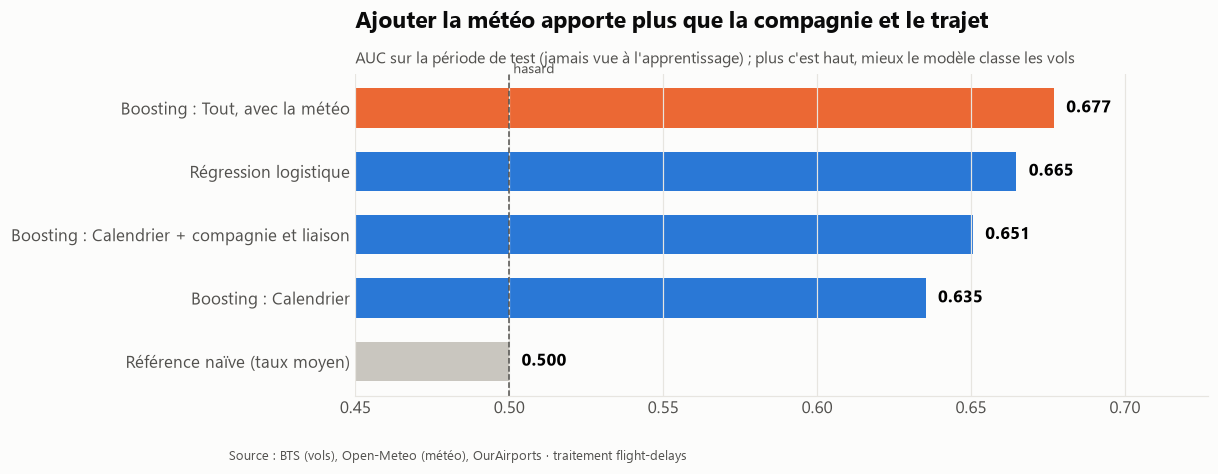

In [4]:
r = results.copy()
r["label"] = r.modele.where(r.modele != "Gradient boosting", "Boosting : " + r.variables)
r = r.sort_values("auc")

fig, ax = plt.subplots(figsize=(10, 3.8))
colors = [fs.ORANGE if "météo" in l else (fs.NEUTRAL if "naïve" in l else fs.BLUE) for l in r.label]
ax.barh(r.label, r.auc, color=colors, height=0.62)
for i, v in enumerate(r.auc):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontweight="bold")
ax.axvline(0.5, color=fs.MUTED, ls="--", lw=1)
ax.text(0.5, len(r) - 0.45, " hasard", color=fs.MUTED, fontsize=9)
ax.set_xlim(0.45, max(r.auc.max() + 0.05, 0.6))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Ajouter la météo apporte plus que la compagnie et le trajet")
fs.subtitle(ax, "AUC sur la période de test (jamais vue à l'apprentissage) ; plus c'est haut, mieux le modèle classe les vols")
fs.source(fig)
fs.save(fig, "12_modeles_auc")

## 3. Les probabilités sont-elles fiables ?

On range les vols de test en 10 groupes selon la probabilité prédite, puis on compare la probabilité moyenne annoncée au taux de retard réellement observé dans chaque groupe. Un modèle bien calibré suit la diagonale.

,predit,observe,vols
0,0.0589,0.0797,76880
1,0.0910,0.1176,76879
2,0.1155,0.1406,76879
3,0.1398,0.1685,76879
4,0.1665,0.1930,76880
5,0.1977,0.2182,76879
6,0.2363,0.2554,76879
7,0.2868,0.2905,76879
8,0.3604,0.3446,76879
9,0.5156,0.4698,76880


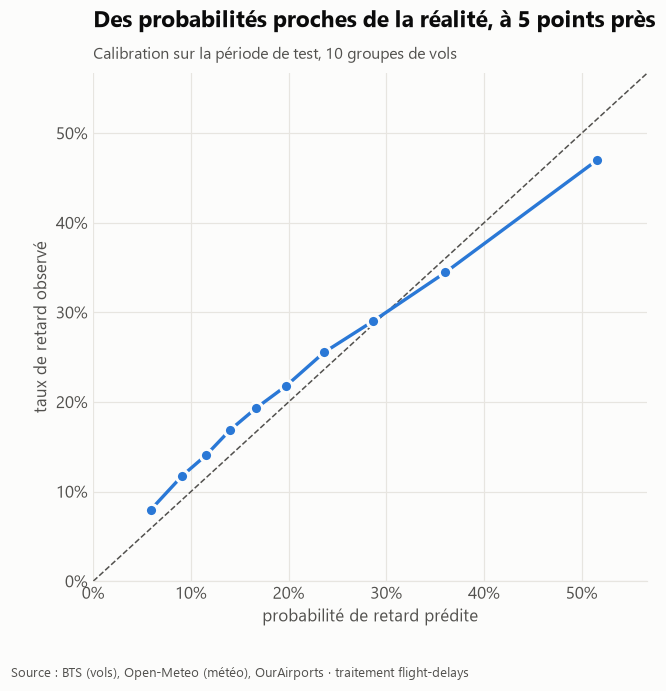

In [5]:
model, p = fitted["Tout, avec la météo"]
cal = fm.calibration(test.is_delayed.values, p)

fig, ax = plt.subplots(figsize=(6.5, 6))
lim = [0, max(cal.predit.max(), cal.observe.max()) * 1.1]
ax.plot(lim, lim, color=fs.MUTED, ls="--", lw=1)
ax.plot(cal.predit, cal.observe, color=fs.BLUE, lw=2.2, marker="o", ms=8, markeredgecolor=fs.SURFACE, markeredgewidth=2)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(axis="x")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlabel("probabilité de retard prédite"); ax.set_ylabel("taux de retard observé")
ax.set_title("Des probabilités proches de la réalité, à 5 points près")
fs.subtitle(ax, "Calibration sur la période de test, 10 groupes de vols")
fs.source(fig)
fs.save(fig, "13_calibration")
cal

## 4. Sur quoi le modèle s'appuie-t-il ?

On brouille un groupe de variables à la fois (en mélangeant ses valeurs entre les vols) et on mesure combien la log loss se dégrade. Plus elle se dégrade, plus le modèle avait besoin de ce groupe.

,groupe,hausse_log_loss
0,Heure de départ,0.0444
4,Météo au départ,0.0214
1,Mois et jour,0.0164
3,"Aéroports (départ, arrivée)",0.0133
2,Compagnie,0.0068


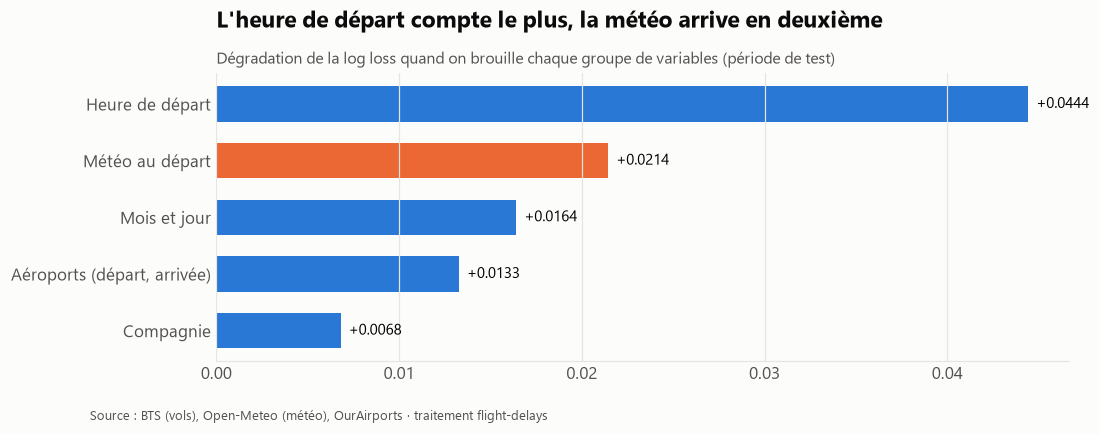

In [6]:
imp = fm.permutation_importance_groups(model, test, fm.IMPORTANCE_GROUPS)

fig, ax = plt.subplots(figsize=(10, 3.4))
imp_sorted = imp.sort_values("hausse_log_loss")
colors = [fs.ORANGE if g == "Météo au départ" else fs.BLUE for g in imp_sorted.groupe]
ax.barh(imp_sorted.groupe, imp_sorted.hausse_log_loss, color=colors, height=0.62)
for i, v in enumerate(imp_sorted.hausse_log_loss):
    ax.text(max(v, 0), i, f"  {v:+.4f}", va="center", fontsize=9.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("L'heure de départ compte le plus, la météo arrive en deuxième")
fs.subtitle(ax, "Dégradation de la log loss quand on brouille chaque groupe de variables (période de test)")
fs.source(fig)
fs.save(fig, "14_importance")
imp

## 5. Export pour Power BI

Les scores, la calibration et l'importance des variables sont écrits dans `data/powerbi/` pour la page « Modèle » du rapport.

In [7]:
from config import EXPORT
EXPORT.mkdir(parents=True, exist_ok=True)
results.to_parquet(EXPORT / "model_scores.parquet", index=False)
cal.to_parquet(EXPORT / "model_calibration.parquet", index=False)
imp.to_parquet(EXPORT / "model_importance.parquet", index=False)
print("Écrit :", ", ".join(f.name for f in sorted(EXPORT.glob("model_*.parquet"))))

Écrit : model_calibration.parquet, model_importance.parquet, model_scores.parquet


## Limites

- La météo utilisée est la météo **observée** à l'heure prévue, pas une prévision : en conditions réelles, une prévision serait moins précise, donc l'apport mesuré de la météo est un **plafond**.
- Le modèle ignore l'état du réseau le jour même (retards en cours, avion qui arrive), qui explique une grande part des retards ; c'est un modèle « à la réservation », pas un modèle en temps réel.

## Ce qu'il faut retenir

- **Un retard est en partie prévisible avant le départ.** Testé sur 2025 sans jamais avoir vu cette année, le gradient boosting atteint une AUC de 0,68 (0,50 = hasard) et une log loss de 0,503, contre 0,537 pour la référence naïve.
- **La météo apporte une information réelle** : l'AUC passe de 0,651 à 0,677 quand on l'ajoute, un gain plus grand que celui de la compagnie et du trajet réunis (de 0,635 à 0,651).
- **L'heure de départ est l'information la plus utile**, devant la météo, le calendrier, les aéroports puis la compagnie.
- **Les probabilités sont bien calibrées**, à moins de 5 points près : le modèle sous-estime légèrement les vols les plus sûrs (le taux de retard est passé de 21,4 % en 2024 à 22,8 % en 2025) et surestime un peu les plus risqués.
- **Mais la prédiction reste modeste** : l'essentiel d'un retard se joue le jour même (avion en retard, contrôle aérien saturé), des informations que ce modèle « à la réservation » n'a pas.